# What the wind adds (2013)

SnapWave with the ERA5 wind field minus SnapWave without wind, same hours, same forcing
(the dynamic pairs of notebook 08), for both offshore sources. This is what the
reconstruction misses today (`hywaves/WIND.md`), and what option 3 there would learn. Hours
where the run with wind did not converge are left out.

In [1]:
import sys

sys.path.insert(0, "..")  # the case folder (utils/)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import results as rs
import xarray as xr
from IPython.display import display

pd.set_option("display.width", 200)
pd.set_option("display.precision", 3)

In [2]:
meta = rs.metamodel("WHACS", "isobaths", False).isel(time=0, drop=True)
sites = meta.sites.values
labels = meta["site_label"]
no_wind, wind, added = {}, {}, {}
for off in rs.OFFSHORE:
    no_wind[off] = rs.dynamic(off, False, sites).assign_coords(meta.coords)
    wind[off] = rs.dynamic(off, True, sites).assign_coords(meta.coords)
    added[off] = wind[off]["hs"] - no_wind[off]["hs"]
    print(f"{off}: {added[off].sizes['sites']} isobath sites, {int(added[off].notnull().sum()):,} valid site-hours")
era5 = rs.wind_at_sites(no_wind["WHACS"])

WHACS: 4977 isobath sites, 41,543,019 valid site-hours
WHACS_cal: 4977 isobath sites, 41,951,133 valid site-hours


## 1 · Where the wind adds most

Mean and p90 of the added Hs per site, and the median ratio of Hs with / without wind.

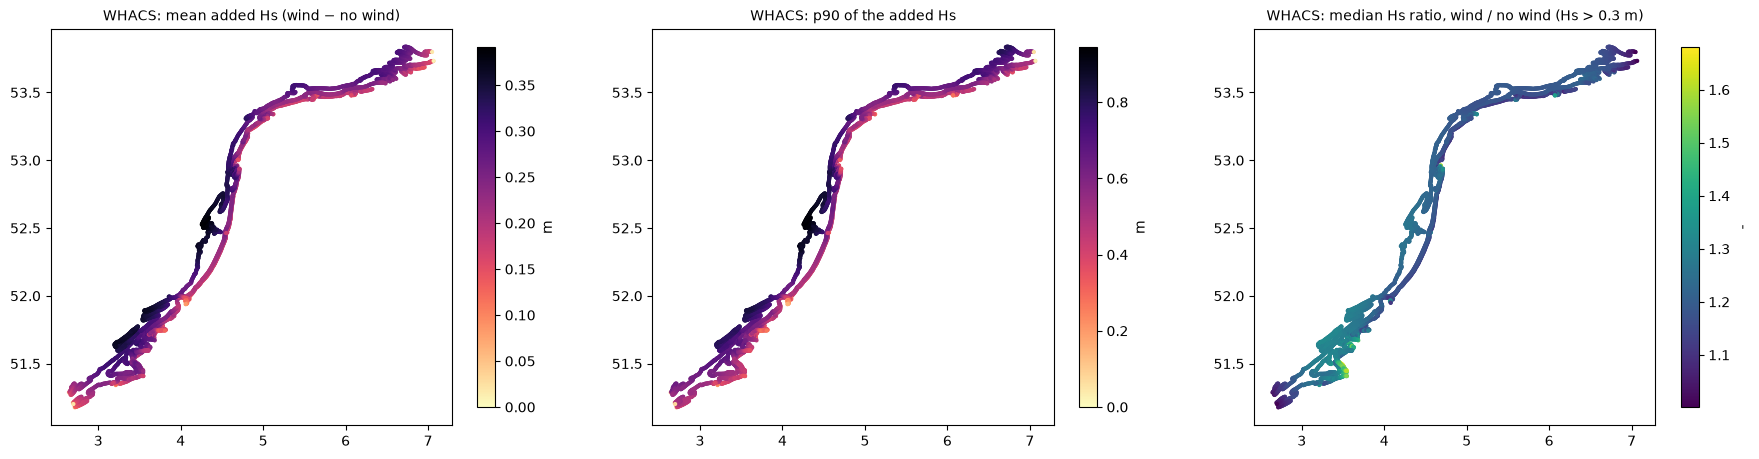

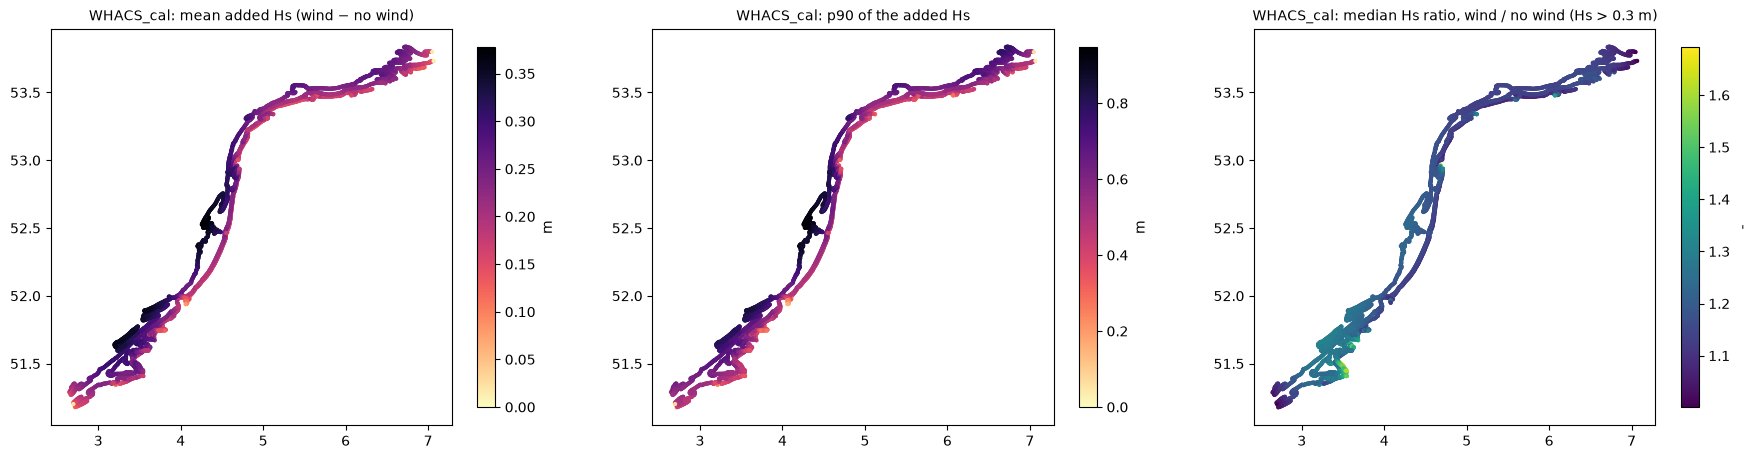

In [3]:
for off in rs.OFFSHORE:
    fig, axes = plt.subplots(1, 3, figsize=(22, 5.5))
    rs.plot_site_map(
        added[off].mean("time"),
        f"{off}: mean added Hs (wind − no wind)",
        "m",
        cmap="magma_r",
        vmin=0,
        ax=axes[0],
    )
    rs.plot_site_map(
        added[off].quantile(0.9, "time").drop_vars("quantile"),
        f"{off}: p90 of the added Hs",
        "m",
        cmap="magma_r",
        vmin=0,
        ax=axes[1],
    )
    ratio = (
        (wind[off]["hs"] / no_wind[off]["hs"])
        .where(no_wind[off]["hs"] > 0.3)
        .median("time")
        .assign_coords(meta["hs"].coords)
    )
    rs.plot_site_map(
        ratio,
        f"{off}: median Hs ratio, wind / no wind (Hs > 0.3 m)",
        "-",
        cmap="viridis",
        ax=axes[2],
    )
    plt.show()

## 2 · By wind speed and direction

Mean added Hs by ERA5 wind speed at the site, and by the direction the wind comes from (16
sectors), per isobath.

These are plain means: they mix how strong the wind is from each direction, how often it blows
from it, and how much sea there already is without wind. Sections 3 and 4 take those apart.

mean added Hs (m) by ERA5 wind speed (m/s)


c              (0, 5]  (5, 10]  (10, 15]  (15, 20]  (20, 30]
WHACS     5m    0.052    0.232     0.366     0.323     0.137
          10m   0.061    0.275     0.527     0.711     0.556
          20m   0.046    0.306     0.648     0.998     1.151
WHACS_cal 5m    0.046    0.223     0.346     0.278     0.074
          10m   0.054    0.267     0.509     0.631     0.374
          20m   0.037    0.294     0.630     0.941     0.905

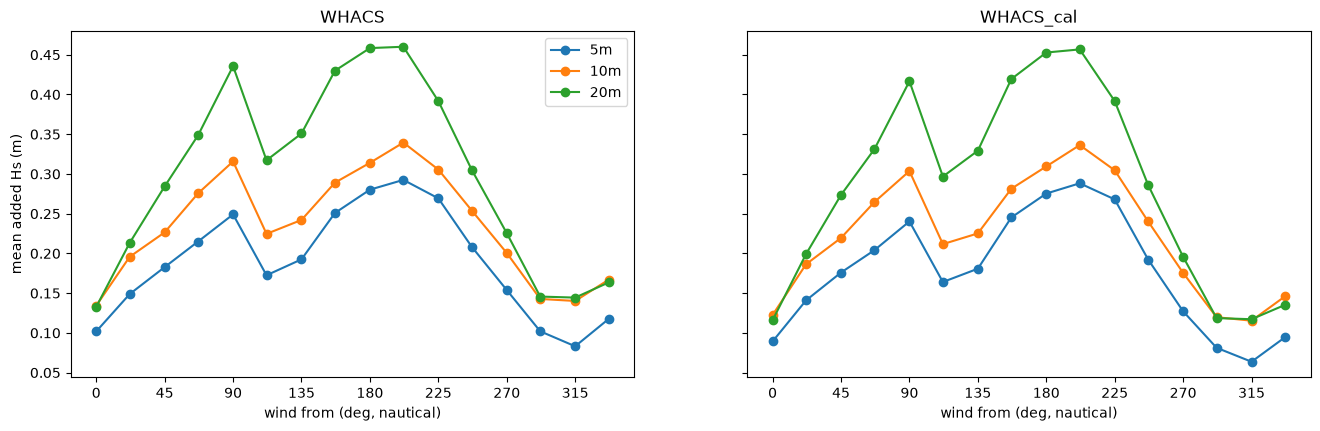

In [4]:
speed_bins = [0, 5, 10, 15, 20, 30]
speed_labels = [str(i) for i in pd.cut([2.5, 7.5, 12.5, 17.5, 25], speed_bins)]
speed_class = xr.DataArray(
    pd.cut(era5["u10"].values.ravel(), speed_bins)
    .astype(str)
    .to_numpy()
    .reshape(era5["u10"].shape),
    dims=era5["u10"].dims,
)
sector = xr.DataArray(
    ((np.round(era5["u10dir"].values / 22.5) % 16) * 22.5).astype(int).astype(str),
    dims=era5["u10dir"].dims,
)
rows = {}
for off in rs.OFFSHORE:
    for label in ("5m", "10m", "20m"):
        sel = meta["site_label"].values == label
        rows[off, label] = rs.by_class(
            added[off].isel(sites=sel), speed_class.isel(sites=sel), speed_labels
        )["mean"]
print("mean added Hs (m) by ERA5 wind speed (m/s)")
display(pd.DataFrame(rows).T)
fig, axes = plt.subplots(1, len(rs.OFFSHORE), figsize=(16, 4.5), sharey=True)
for ax, off in zip(axes, rs.OFFSHORE):
    for label in ("5m", "10m", "20m"):
        sel = meta["site_label"].values == label
        t = rs.by_class(added[off].isel(sites=sel), sector.isel(sites=sel))
        t.index = t.index.astype(int)
        t = t.sort_index()
        ax.plot(t.index, t["mean"], "o-", label=label)
    ax.set(xlabel="wind from (deg, nautical)", title=off, xticks=range(0, 360, 45))
axes[0].set_ylabel("mean added Hs (m)")
axes[0].legend()
plt.show()

## 3 · By direction, at the same wind speed

Only the hours with 8-14 m/s at the site, so every direction has the same wind. With wind from
the sea (W to N) the boundary already brings a grown sea (WHACS grew it over the North Sea):
the local wind adds energy, but little Hs on top of a big sea (ΔHs ≈ ΔE / 2Hs). From the land
side (E to S) the run without wind has little sea, and everything grows inside the domain.

In [5]:
SPEED = (8, 14)
windy = (era5["u10"] >= SPEED[0]) & (era5["u10"] < SPEED[1])
wsec = rs.sector(era5["u10dir"])
rows = {}
for off in rs.OFFSHORE:
    h0, h1 = no_wind[off]["hs"], wind[off]["hs"]
    for label in ("5m", "20m"):
        sel = labels == label
        for name, values in {"Hs no wind": h0, "added Hs": h1 - h0, "added energy (m²)": h1**2 - h0**2}.items():
            rows[off, label, name] = rs.mean_by(values.where(windy & sel), wsec)
table = pd.DataFrame(rows).T
table.columns.name = "wind from (deg)"
print(f"means over the site-hours with U10 {SPEED[0]}-{SPEED[1]} m/s")
display(table)

means over the site-hours with U10 8-14 m/s


wind from (deg)                    0      45     90     135    180    225    270    315
WHACS     5m  Hs no wind         1.302  0.744  0.496  0.198  0.587  0.888  1.323  1.453
              added Hs           0.199  0.355  0.401  0.426  0.430  0.404  0.245  0.146
              added energy (m²)  0.502  0.612  0.522  0.348  0.695  0.870  0.678  0.392
          20m Hs no wind         1.717  1.072  0.812  0.447  0.936  1.293  1.703  1.855
              added Hs           0.333  0.580  0.681  0.708  0.643  0.572  0.402  0.274
              added energy (m²)  1.186  1.530  1.442  1.055  1.624  1.862  1.593  1.127
WHACS_cal 5m  Hs no wind         1.356  0.767  0.523  0.200  0.579  0.891  1.394  1.524
              added Hs           0.163  0.342  0.391  0.425  0.434  0.403  0.198  0.099
              added energy (m²)  0.397  0.592  0.510  0.345  0.699  0.863  0.539  0.245
          20m Hs no wind         1.833  1.107  0.869  0.447  0.921  1.285  1.837  2.023
              added Hs           0.294  0.565  0.664  0.708  0.650  0.577  0.355  0.224
              added energy (m²)  1.081  1.508  1.426  1.051  1.634  1.864  1.471  0.992

## 4 · By stretch of coast

The same hours (8-14 m/s), split by stretch of coast (`rs.COAST_REGIONS`, by latitude) and, in
the maps, by wind direction. The added sea depends on the fetch inside the domain: wind along
the coast (SW, NE) grows it along the coast, offshore wind (E, SE) grows it towards the outer
sites, most where the 20 m isobath is far from the coast (Belgium-Zeeland).

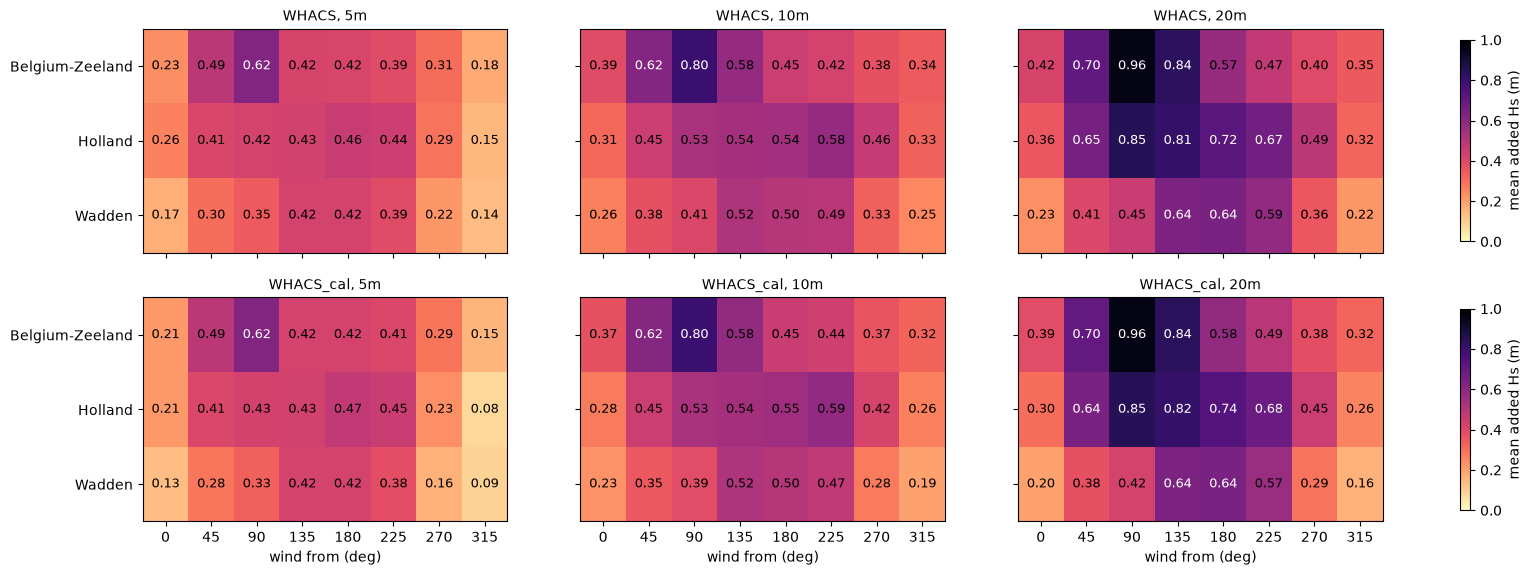

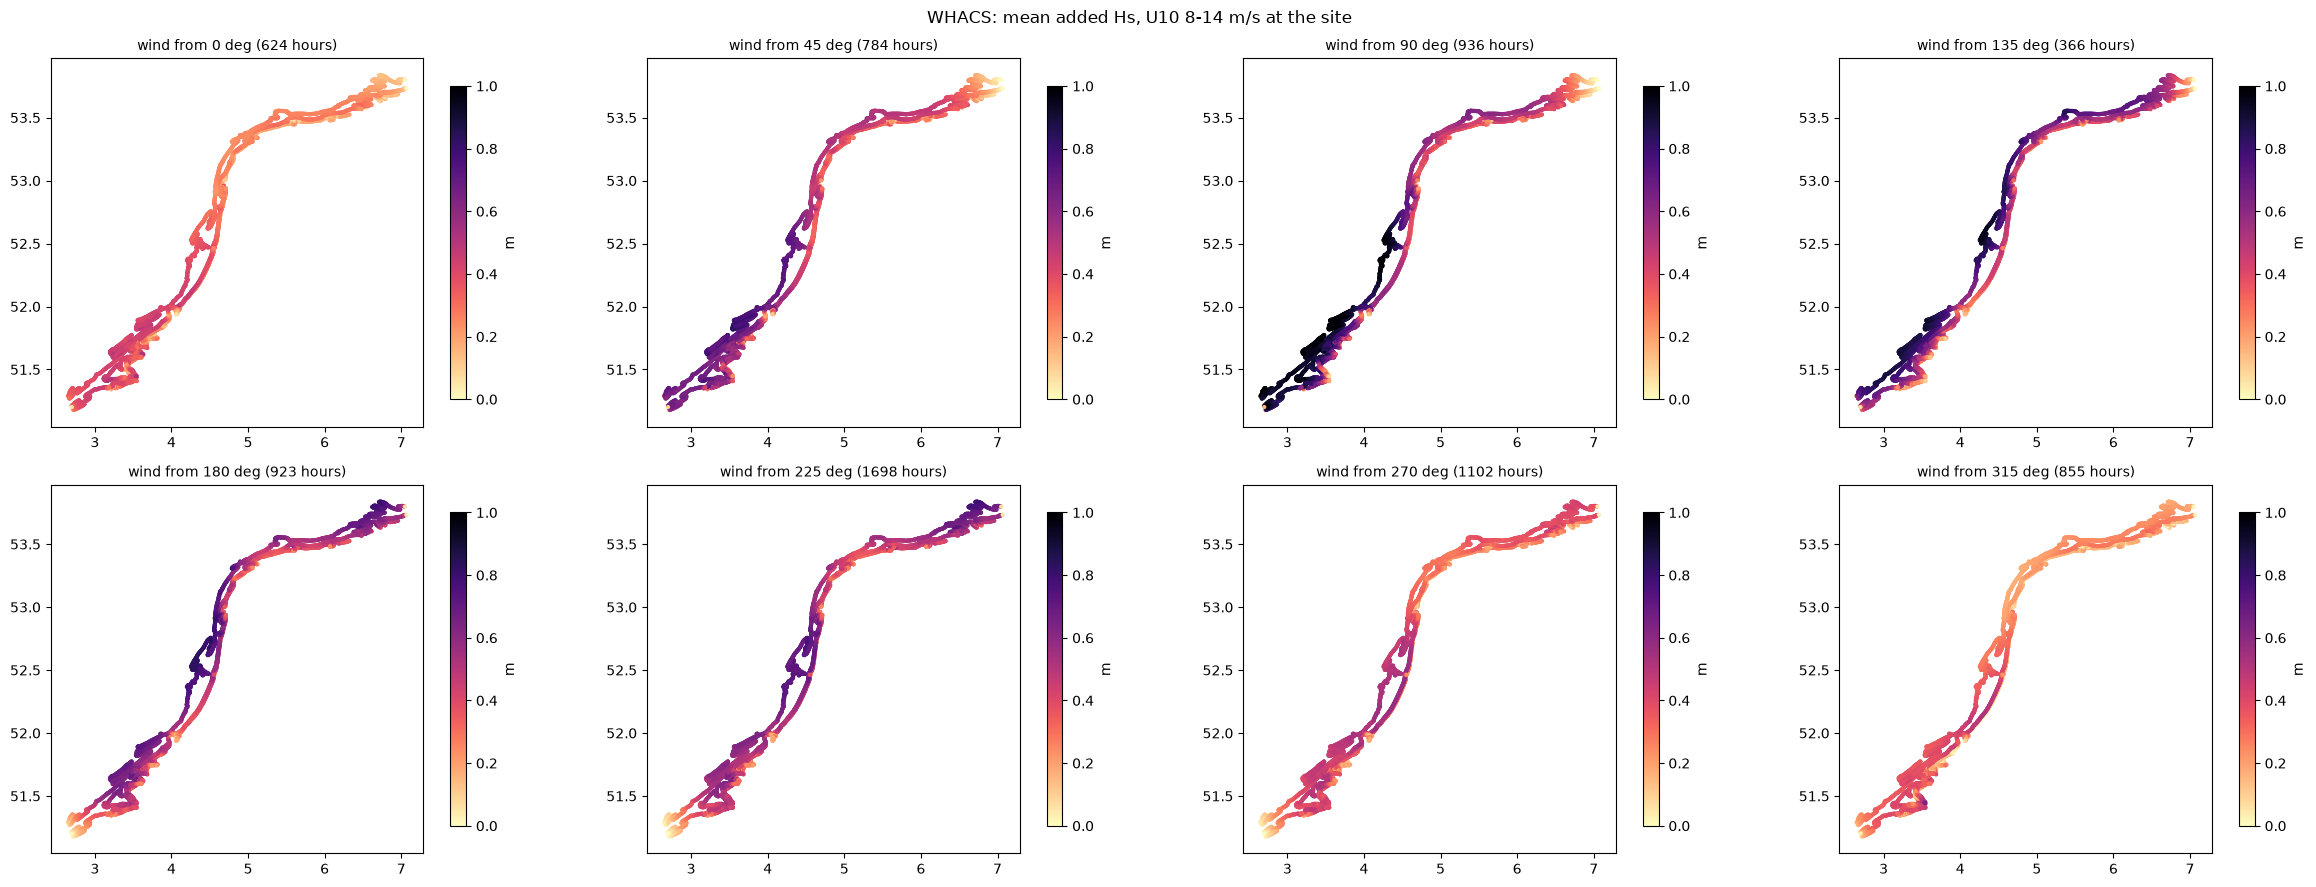

In [6]:
region = rs.coast_region(meta)
order = list(rs.COAST_REGIONS)
fig, axes = plt.subplots(len(rs.OFFSHORE), 3, figsize=(20, 3.2 * len(rs.OFFSHORE)), sharex=True, sharey=True)
for row, off in zip(axes, rs.OFFSHORE):
    for ax, label in zip(row, ("5m", "10m", "20m")):
        t = rs.mean_by(added[off].where(windy & (labels == label)), region, wsec).unstack().reindex(order)
        im = ax.imshow(t.values, cmap="magma_r", vmin=0, vmax=1.0, aspect="auto")
        for (i, j), v in np.ndenumerate(t.values):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9, color="w" if v > 0.6 else "k")
        ax.set_xticks(range(t.shape[1]), t.columns)
        ax.set_yticks(range(len(order)), order)
        ax.set_title(f"{off}, {label}", fontsize=10)
    fig.colorbar(im, ax=row, label="mean added Hs (m)", shrink=0.9)
for ax in axes[-1]:
    ax.set_xlabel("wind from (deg)")
plt.show()

off = "WHACS"
fig, axes = plt.subplots(2, 4, figsize=(24, 9))
for ax, s in zip(axes.ravel(), range(0, 360, 45)):
    sel = windy & (wsec == s)
    rs.plot_site_map(added[off].where(sel).mean("time"), f"wind from {s} deg ({int(sel.any('sites').sum())} hours)",
                     "m", cmap="magma_r", vmin=0, vmax=1.0, ax=ax)
fig.suptitle(f"{off}: mean added Hs, U10 {SPEED[0]}-{SPEED[1]} m/s at the site", fontsize=12)
fig.tight_layout()
plt.show()

## 5 · Analogs: what SnapWave does in a given situation

Pick a situation (wind speed and direction over the domain, Hs at 20 m without wind): the
closest hours of 2013 (`rs.analog_hours`, distance scaled by `rs.ANALOG_SCALES`) and their mean
Hs without and with wind, the added Hs, and at the buoys the error of the run with wind (title:
the median error of both runs). The figure title says how close the analogs are; check it
before reading the maps.

{'WHACS': 8347, 'WHACS_cal': 8429} hours with both runs


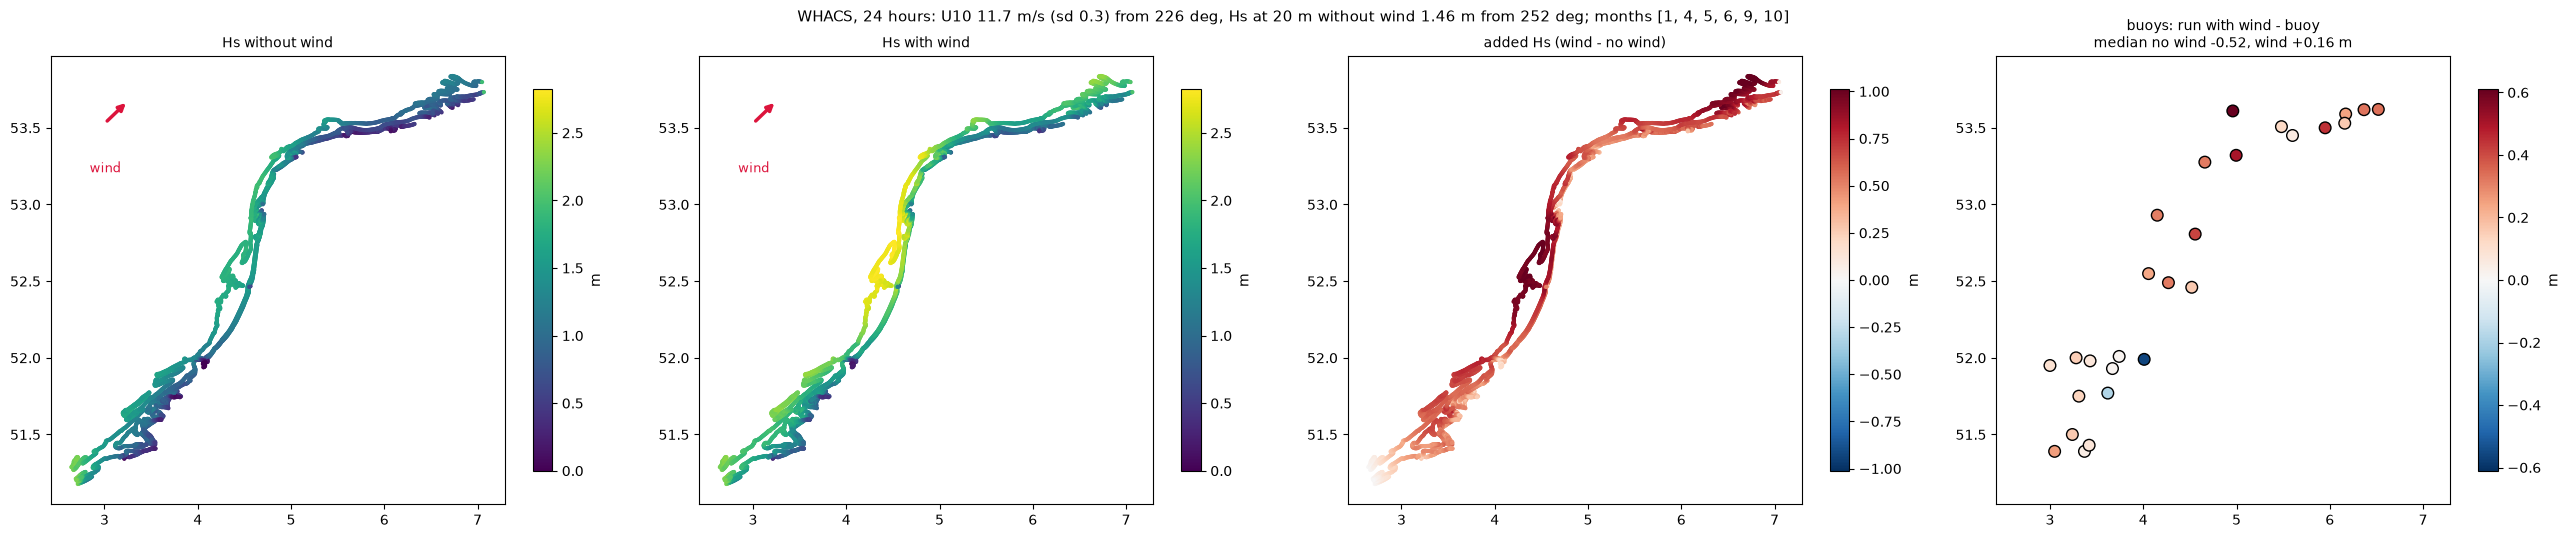

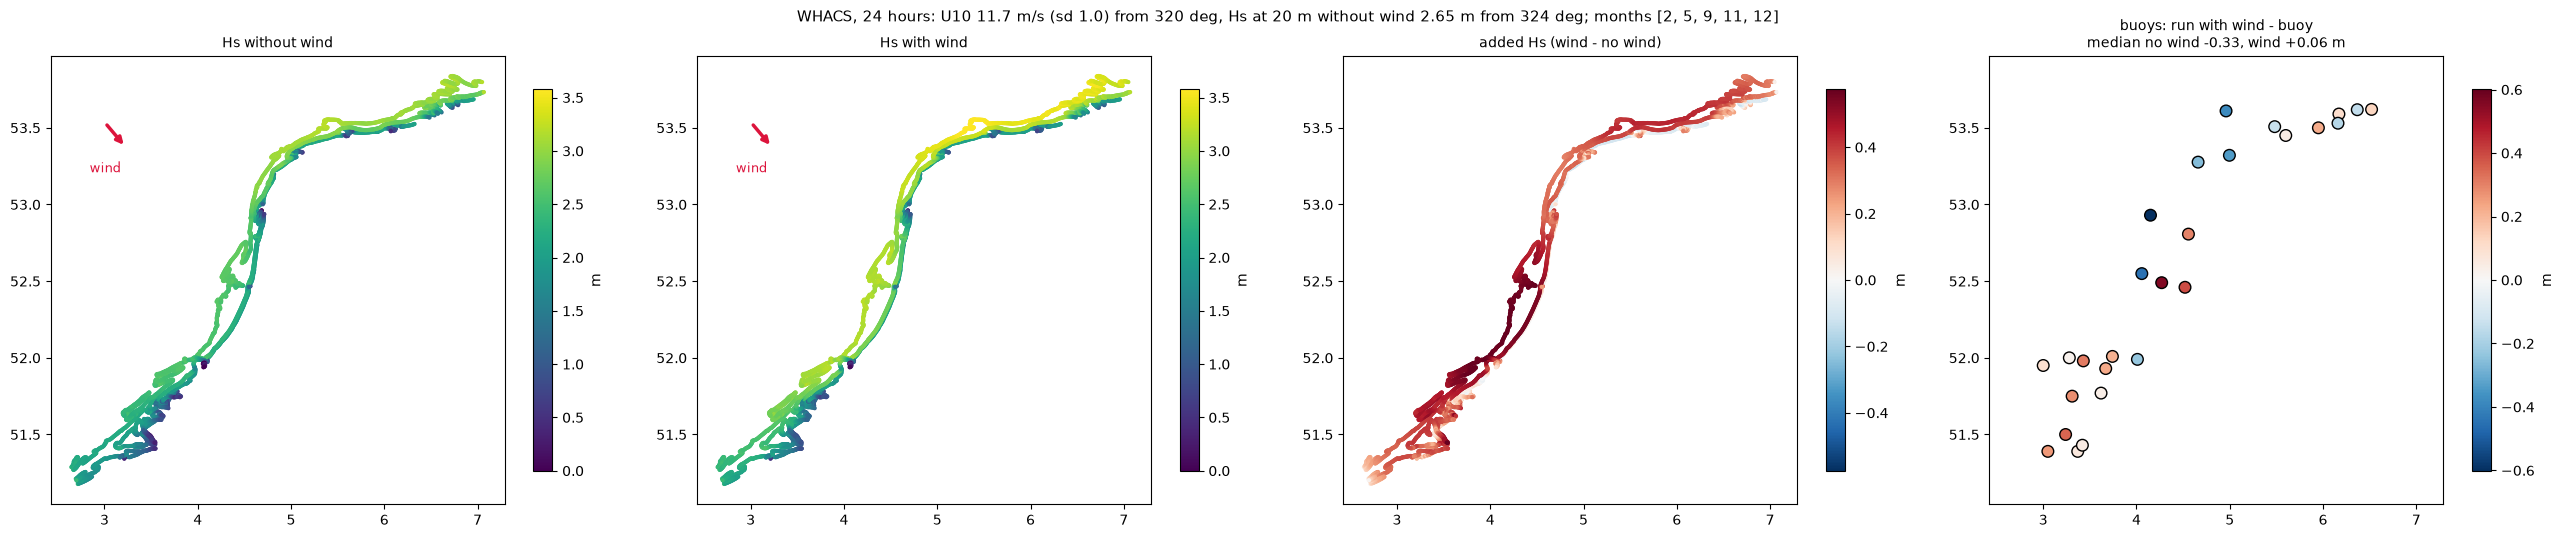

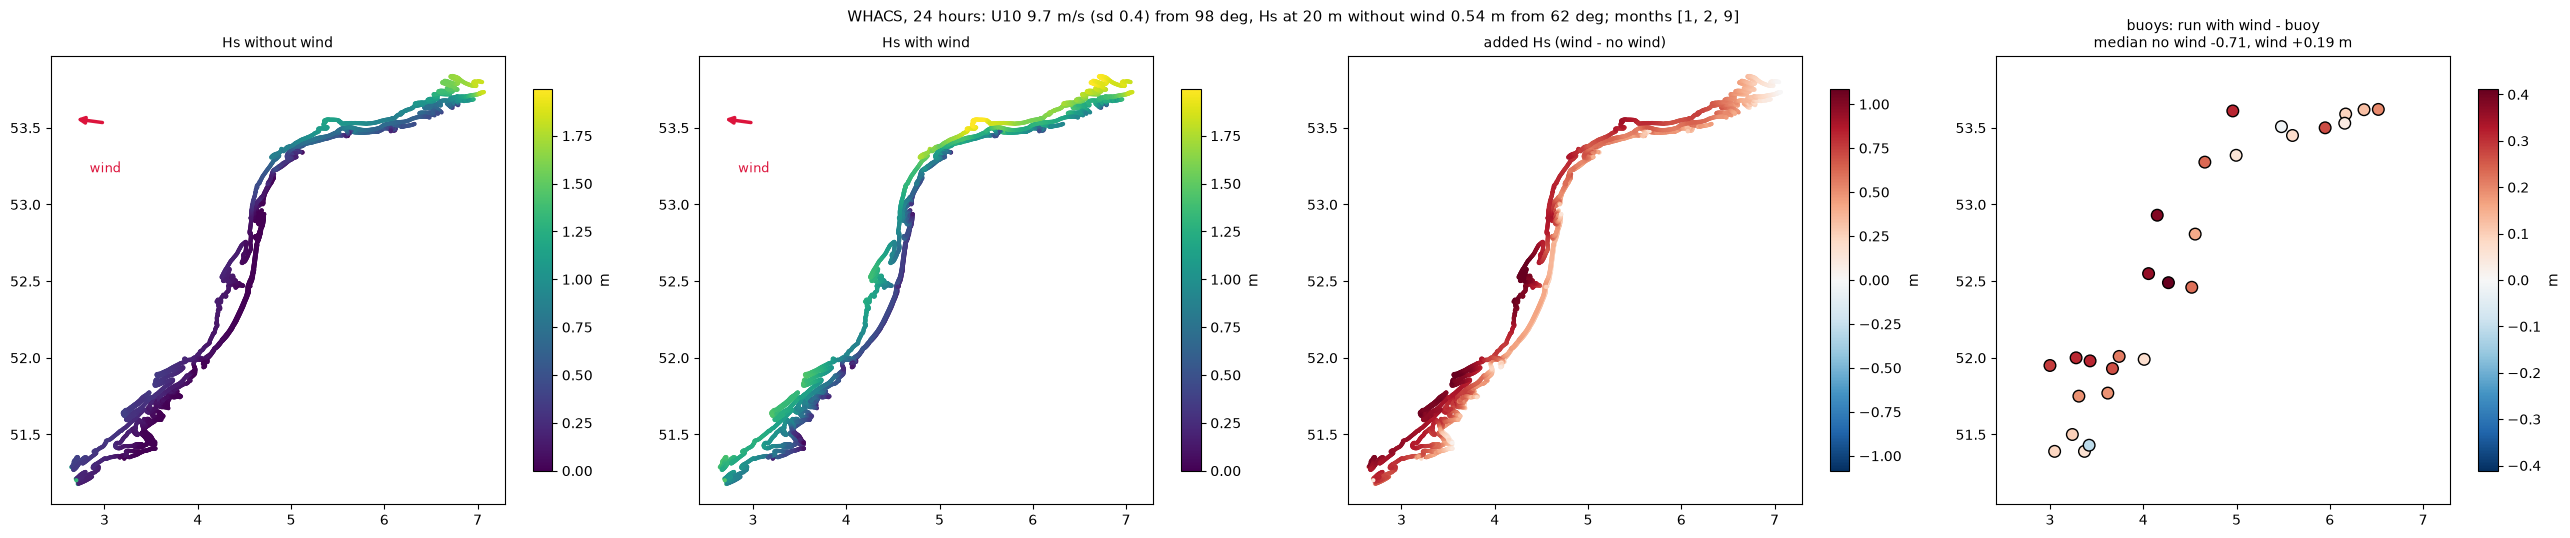

In [7]:
conditions = {off: rs.hour_conditions(no_wind[off], wind[off], era5, labels) for off in rs.OFFSHORE}
buoy = rs.buoys(["hs"])
buoy_error = {
    off: {name: rs.dynamic(off, w, buoy.sites.values)["hs"].reindex(time=buoy.time) - buoy["hs"]
          for name, w in (("no wind", False), ("wind", True))}
    for off in rs.OFFSHORE
}
print({off: len(c) for off, c in conditions.items()}, "hours with both runs")

for target in ({"u10": 12, "u10dir": 225, "hs20": 1.5},   # SW, along the coast
               {"u10": 12, "u10dir": 315, "hs20": 2.5},   # NW, from the sea
               {"u10": 10, "u10dir": 100, "hs20": 0.5}):  # E, offshore wind
    hours = rs.analog_hours(conditions["WHACS"], k=24, **target)
    rs.plot_analogs(hours, no_wind["WHACS"]["hs"], wind["WHACS"]["hs"], buoy_error["WHACS"], title="WHACS, ")
    plt.show()

Interactive (needs a live kernel): move the sliders, the figure updates on release.

In [8]:
import ipywidgets as widgets


def explore(offshore: str, u10: float, u10dir: float, hs20: float, k: int) -> None:
    hours = rs.analog_hours(conditions[offshore], k=k, u10=u10, u10dir=u10dir, hs20=hs20)
    rs.plot_analogs(hours, no_wind[offshore]["hs"], wind[offshore]["hs"], buoy_error[offshore], title=f"{offshore}, ")
    plt.show()


slider = dict(continuous_update=False)
widgets.interact(
    explore,
    offshore=list(rs.OFFSHORE),
    u10=widgets.FloatSlider(value=12, min=2, max=20, step=0.5, description="U10 (m/s)", **slider),
    u10dir=widgets.IntSlider(value=225, min=0, max=345, step=15, description="wind from", **slider),
    hs20=widgets.FloatSlider(value=1.5, min=0.1, max=4, step=0.1, description="Hs 20 m", **slider),
    k=widgets.IntSlider(value=24, min=6, max=96, step=6, description="hours", **slider),
);

interactive(children=(Dropdown(description='offshore', options=('WHACS', 'WHACS_cal'), value='WHACS'), FloatSl…

## 6 · Against the buoys, by wind direction

Mean Hs error of both dynamic runs at the buoys (run − buoy), by the ERA5 wind at the buoy;
pairs valid in both runs. Without wind the error is how much sea the wind should add; with wind,
whether SnapWave adds the right amount from each direction.

In [9]:
bwind = rs.wind_at_sites(buoy)
bsec = rs.sector(bwind["u10dir"]).rename("from (deg)")
bspeed = xr.where(bwind["u10"] >= 8, "U10 >= 8", "U10 < 8").rename("ERA5 wind")
rows = {}
for off in rs.OFFSHORE:
    both = buoy_error[off]["wind"].notnull() & buoy_error[off]["no wind"].notnull()
    for name, err in buoy_error[off].items():
        rows[off, name] = rs.mean_by(err.where(both), bspeed, bsec)
table = pd.DataFrame(rows).T
table.columns.names = ["ERA5 wind", "from (deg)"]
print("mean Hs error at the buoys, run - buoy (m)")
display(table)

mean Hs error at the buoys, run - buoy (m)


ERA5 wind         U10 < 8                                                  U10 >= 8                                                 
from (deg)            0      45     90     135    180    225    270    315      0      45     90     135    180    225    270    315
WHACS     no wind  -0.068 -0.134 -0.149 -0.126 -0.114 -0.097 -0.080 -0.049   -0.189 -0.430 -0.614 -0.621 -0.384 -0.286 -0.259 -0.256
          wind      0.045  0.061  0.057  0.051  0.106  0.091  0.034  0.028    0.135  0.188  0.170  0.196  0.326  0.293  0.126  0.018
WHACS_cal no wind  -0.033 -0.113 -0.125 -0.102 -0.101 -0.087 -0.049 -0.003   -0.077 -0.401 -0.574 -0.619 -0.394 -0.288 -0.125 -0.070
          wind      0.068  0.072  0.066  0.059  0.109  0.095  0.054  0.063    0.211  0.202  0.193  0.197  0.322  0.296  0.219  0.158

## 7 · By sea state, and the 5 m isobath

Added Hs by each site's Hs quantile class (classes from the run without wind). At the 5 m
isobath the wind lowers Hs in the rare hours with Hs ≥ 3 m without wind: the changes of
every variable there show why.

In [10]:
order = ["p0-50", "p50-90", "p90-99", "p99-100"]
rows = {}
for off in rs.OFFSHORE:
    classes = rs.rank_classes(rs.hs_rank(no_wind[off]))
    for label in ("5m", "10m", "20m"):
        sel = meta["site_label"].values == label
        rows[off, label] = rs.by_class(
            added[off].isel(sites=sel), classes.isel(sites=sel), order
        )["mean"]
print("mean added Hs (m) by each site's Hs quantile class")
display(pd.DataFrame(rows).T)
sel5 = meta["site_label"].values == "5m"
for off in rs.OFFSHORE:
    big = (no_wind[off]["hs"] >= 3).isel(sites=sel5)
    changes = {}
    for variable in ("hs", "tp", "dir", "spr"):
        d = (wind[off][variable] - no_wind[off][variable]).isel(sites=sel5)
        if variable == "dir":
            d = (d + 180) % 360 - 180
        changes[variable] = float(d.where(big).mean())
    print(
        f"{off}, 5 m, hours with Hs >= 3 m without wind ({int(big.sum()):,} site-hours): mean change",
        {k: round(v, 3) for k, v in changes.items()},
    )

mean added Hs (m) by each site's Hs quantile class


c              p0-50  p50-90  p90-99  p99-100
WHACS     5m   0.218   0.184   0.152    0.023
          10m  0.235   0.229   0.327    0.359
          20m  0.289   0.290   0.408    0.568
WHACS_cal 5m   0.210   0.174   0.117   -0.018
          10m  0.225   0.222   0.293    0.269
          20m  0.276   0.283   0.356    0.487

WHACS, 5 m, hours with Hs >= 3 m without wind (151 site-hours): mean change {'hs': -0.195, 'tp': -3.209, 'dir': -0.608, 'spr': 1.521}
WHACS_cal, 5 m, hours with Hs >= 3 m without wind (381 site-hours): mean change {'hs': -0.282, 'tp': -3.733, 'dir': -0.802, 'spr': 1.639}


## 8 · Hours that do not converge with wind

Non-converged hours are NaN in the run with wind: when they happen and what the sea and wind
were (as `tmp/check_dynamic_run.py`).

In [11]:
mean_wind = era5["u10"].mean("sites").to_series()
for off in rs.OFFSHORE:
    missing = wind[off]["hs"].isnull().all("sites") & no_wind[off]["hs"].notnull().any(
        "sites"
    )
    hours = pd.DatetimeIndex(wind[off]["time"].values[missing.values])
    table = pd.DataFrame(
        {
            "site-mean Hs, no wind": no_wind[off]["hs"].mean("sites").to_series(),
            "site-mean U10": mean_wind,
        }
    )
    print(f"{off}: {len(hours)} hours without a converged run with wind")
    display(
        pd.concat(
            {"all hours": table.median(), "non-converged": table.loc[hours].median()},
            axis=1,
        ).T.rename(index=lambda i: f"{i} (median)")
    )
    print(
        pd.Series(hours.month)
        .value_counts()
        .sort_index()
        .rename("hours per month")
        .to_frame()
        .T
    )

WHACS: 413 hours without a converged run with wind


,"site-mean Hs, no wind",site-mean U10
all hours (median),0.680,6.469
non-converged (median),0.318,3.474


                 1   2   3   4   5   6   7   8   9   10  11  12
hours per month  28  54  40  27  40  30  44  87  23  25   6   9
WHACS_cal: 331 hours without a converged run with wind


,"site-mean Hs, no wind",site-mean U10
all hours (median),0.690,6.469
non-converged (median),0.354,3.539


                 1   2   3   4   5   6   7   8   9   10  11  12
hours per month  28  46  37  26  31  27  37  65  13  10   4   7
